In [1]:
%pip install pandas matplotlib ipython-sql sqlalchemy

Defaulting to user installation because normal site-packages is not writeable

   ---------------------------------------- 0/4 [ipython-genutils]
   ---------------------------------------- 0/4 [ipython-genutils]
   ---------- ----------------------------- 1/4 [sqlparse]
   ---------- ----------------------------- 1/4 [sqlparse]
   ---------- ----------------------------- 1/4 [sqlparse]
   ---------- ----------------------------- 1/4 [sqlparse]
   ---------- ----------------------------- 1/4 [sqlparse]
   -------------------- ------------------- 2/4 [prettytable]
   ------------------------------ --------- 3/4 [ipython-sql]
   ---------------------------------------- 4/4 [ipython-sql]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("restaurant.db")

conn.execute("""
CREATE TABLE IF NOT EXISTS restaurants (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    name TEXT,
    cuisine TEXT,
    rating REAL
)
""")

if conn.execute("SELECT COUNT(*) FROM restaurants").fetchone()[0] == 0:
    conn.executemany("""
        INSERT INTO restaurants (name, cuisine, rating)
        VALUES (?, ?, ?)
    """, [
        ("Spice Garden", "South Indian", 4.5),
        ("Dragon Palace", "Chinese", 4.2),
        ("Food Corner", "North Indian", 3.8),
        ("Pizza House", "Italian", 4.4),
        ("Tandoori Treat", "North Indian", 4.6),
        ("Green Bowl", "Healthy Food", 4.1)
    ])
    conn.commit()

conn.close()

conn = sqlite3.connect("movies.db")

conn.execute("""
CREATE TABLE IF NOT EXISTS movies (
    id INTEGER PRIMARY KEY,
    title TEXT,
    rating REAL
)
""")

if conn.execute("SELECT COUNT(*) FROM movies").fetchone()[0] == 0:
    conn.executemany("""
        INSERT INTO movies (title, rating) VALUES (?, ?)
    """, [
        ("Inception", 8.8),
        ("Interstellar", 8.7),
        ("The Dark Knight", 9.0),
        ("Example Movie", 7.5),
        ("The Matrix", 8.7)
    ])
    conn.commit()

conn.close()

conn = sqlite3.connect("zomato.db")

conn.execute("""
CREATE TABLE IF NOT EXISTS orders (
    order_id INTEGER PRIMARY KEY,
    food_item TEXT,
    amount REAL
)
""")

if conn.execute("SELECT COUNT(*) FROM orders").fetchone()[0] == 0:
    conn.executemany("""
        INSERT INTO orders VALUES (?, ?, ?)
    """, [
        (1, "Pizza", 250),
        (2, "Burger", 120),
        (3, "Biryani", 200),
        (4, "Pizza", 250),
        (5, "Dosa", 100),
        (6, "Biryani", 200),
        (7, "Burger", 120),
        (8, "Pizza", 250),
        (9, "Biryani", 200),
        (10, "Pizza", 250)
    ])
    conn.commit()

conn.close()

conn = sqlite3.connect("ipl.db")

conn.execute("""
CREATE TABLE IF NOT EXISTS matches (
    match_id INTEGER PRIMARY KEY,
    team1 TEXT,
    team2 TEXT
)
""")

if conn.execute("SELECT COUNT(*) FROM matches").fetchone()[0] == 0:
    conn.executemany("""
        INSERT INTO matches VALUES (?, ?, ?)
    """, [
        (1, "MI", "CSK"),
        (2, "RCB", "KKR"),
        (3, "MI", "RCB"),
        (4, "CSK", "KKR"),
        (5, "MI", "KKR"),
        (6, "RCB", "CSK"),
        (7, "MI", "CSK"),
        (8, "KKR", "RCB")
    ])
    conn.commit()

conn.close()

conn = sqlite3.connect("users_orders.db")

conn.execute("""
CREATE TABLE IF NOT EXISTS users (
    user_id INTEGER PRIMARY KEY,
    username TEXT
)
""")

conn.execute("""
CREATE TABLE IF NOT EXISTS orders (
    order_id INTEGER PRIMARY KEY,
    user_id INTEGER,
    product TEXT
)
""")

if conn.execute("SELECT COUNT(*) FROM users").fetchone()[0] == 0:
    conn.executemany("INSERT INTO users VALUES (?, ?)", [
        (1, "Rahul"),
        (2, "Priya"),
        (3, "Amit"),
        (4, "Neha")
    ])

if conn.execute("SELECT COUNT(*) FROM orders").fetchone()[0] == 0:
    conn.executemany("INSERT INTO orders VALUES (?, ?, ?)", [
        (1, 1, "Pizza"),
        (2, 1, "Burger"),
        (3, 1, "Dosa"),
        (4, 1, "Pizza"),
        (5, 1, "Biryani"),
        (6, 1, "Burger"),
        (7, 2, "Pizza"),
        (8, 2, "Dosa"),
        (9, 2, "Burger"),
        (10, 3, "Pizza"),
        (11, 3, "Biryani"),
        (12, 3, "Dosa"),
        (13, 3, "Burger"),
        (14, 3, "Pizza"),
        (15, 3, "Dosa"),
        (16, 4, "Burger")
    ])

conn.commit()
conn.close()

print("All sample databases and tables are ready.")

All sample databases and tables are ready.


Task 1 — Load restaurant data using read_sql()

In [3]:
conn = sqlite3.connect("restaurant.db")

df_restaurants = pd.read_sql(
    "SELECT * FROM restaurants", conn
)

print("First 5 restaurant records:")
display(df_restaurants.head())

conn.close()

First 5 restaurant records:


,id,name,cuisine,rating
0,1,Spice Garden,South Indian,4.5
1,2,Dragon Palace,Chinese,4.2
2,3,Food Corner,North Indian,3.8
3,4,Pizza House,Italian,4.4
4,5,Tandoori Treat,North Indian,4.6


Task 2 — Use SQL magic to find movies rated above 8

In [4]:
%load_ext sql

In [5]:
%sql sqlite:///movies.db

In [7]:
%config SqlMagic.style = '_DEPRECATED_DEFAULT'

In [8]:
%%sql
SELECT *
FROM movies
WHERE rating > 8;

 * sqlite:///movies.db
Done.


id,title,rating
1,Inception,8.8
2,Interstellar,8.7
3,The Dark Knight,9.0
5,The Matrix,8.7


Task 3 — Find the top 3 most ordered food items

In [9]:
conn = sqlite3.connect("zomato.db")

df_orders = pd.read_sql("""
    SELECT *
    FROM orders
    ORDER BY order_id DESC
    LIMIT 100
""", conn)

print("Last 100 orders:")
display(df_orders)

top_items = df_orders["food_item"].value_counts().head(3)

print("Top 3 most ordered food items:")
display(top_items)

conn.close()

Last 100 orders:


,order_id,food_item,amount
0,10,Pizza,250.0
1,9,Biryani,200.0
2,8,Pizza,250.0
3,7,Burger,120.0
4,6,Biryani,200.0
5,5,Dosa,100.0
6,4,Pizza,250.0
7,3,Biryani,200.0
8,2,Burger,120.0
9,1,Pizza,250.0


Top 3 most ordered food items:


food_item
Pizza      4
Biryani    3
Burger     2
Name: count, dtype: int64

Task 4 — IPL matches bar chart

Matches played by each team:


team1
CSK    4
KKR    4
MI     4
RCB    4
Name: count, dtype: int64

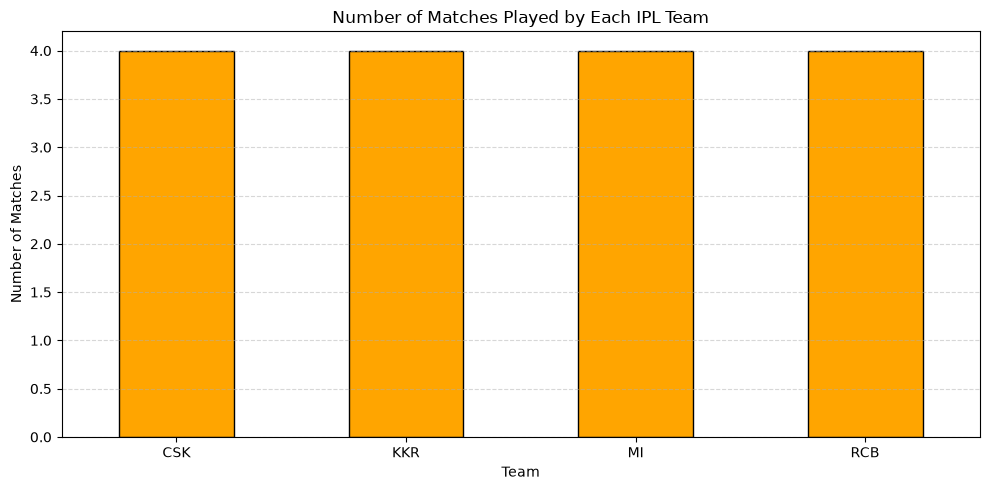

In [10]:
conn = sqlite3.connect("ipl.db")

df_matches = pd.read_sql(
    "SELECT * FROM matches", conn
)

# Count each team's appearances in both columns
team1_count = df_matches["team1"].value_counts()
team2_count = df_matches["team2"].value_counts()

team_matches = team1_count.add(
    team2_count, fill_value=0
).astype(int)

team_matches = team_matches.sort_values(ascending=False)

print("Matches played by each team:")
display(team_matches)

# Plot the bar chart
plt.figure(figsize=(10, 5))
team_matches.plot(kind="bar", color="orange", edgecolor="black")

plt.title("Number of Matches Played by Each IPL Team")
plt.xlabel("Team")
plt.ylabel("Number of Matches")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

conn.close()

Task 5 — Find users who placed more than 5 orders

In [11]:
conn = sqlite3.connect("users_orders.db")

query = """
SELECT
    u.user_id,
    u.username,
    COUNT(o.order_id) AS total_orders
FROM users AS u
INNER JOIN orders AS o
    ON u.user_id = o.user_id
GROUP BY u.user_id, u.username
HAVING COUNT(o.order_id) > 5
ORDER BY total_orders DESC
"""

df_users = pd.read_sql(query, conn)

print("Users who placed more than 5 orders:")
display(df_users)

conn.close()

Users who placed more than 5 orders:


,user_id,username,total_orders
0,1,Rahul,6
1,3,Amit,6
